# From parabolic equations to backward stochastic representations

A semilinear parabolic equation can be written as:

$$
\partial_t u(t,x)+\mu(t,x)^{\mathsf T}\nabla_x u(t,x)+\frac12\operatorname{tr}\!\left(\sigma(t,x)\sigma(t,x)^{\mathsf T}\nabla_x^2u(t,x)\right)+f\!\left(t,x,u(t,x),\sigma(t,x)^{\mathsf T}\nabla_xu(t,x)\right)=0,
\qquad u(T,x)=g(x).
$$

Here, $t\in[0,T]$ is time; $x\in\mathbb R^d$ is the state; $u(t,x)$ is the unknown value; $\mu(t,x)$ is the drift; $\sigma(t,x)$ is the diffusion matrix; $\nabla_xu$ and $\nabla_x^2u$ are the gradient and Hessian; $f$ is the driver; $g$ is the terminal value; $d$ is the state dimension; and $\operatorname{tr}$ is the matrix trace.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
from pathlib import Path
import inspect
import math
import re
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image

warnings.filterwarnings("ignore")
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
ROOT = Path.cwd().parents[1]

from RiskLabAI.pde import BlackScholesBarenblatt, DeepBSDE, DeepTimeSetTransformer, Equation, FBSDESolver, FBSNNNetwork, FBSNNolver, FBSNNSolver, HJBLQ, ISAB, MAB, Net1, PMA, PricingDefaultRisk, PricingDiffRate, SAB, TimeDependentNetwork, TimeDependentNetworkMonteCarlo, TimeNet, TimeNetForSet, initialize_weights

FIGURES = ROOT / "outputs" / "figures" / "29_deep_bsde"
TABLES = ROOT / "outputs" / "tables" / "29_deep_bsde"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def count_parameters(model):
    return int(sum(parameter.numel() for parameter in model.parameters()))

def finite_sequence(values):
    array = np.asarray(values, dtype=float)
    return bool(array.size and np.all(np.isfinite(array)))

device = torch.device("cpu")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## The Released Equation Families

In [2]:
public_names = ["Equation", "PricingDefaultRisk", "HJBLQ", "BlackScholesBarenblatt", "PricingDiffRate", "TimeNet", "Net1", "MAB", "SAB", "ISAB", "PMA", "TimeNetForSet", "DeepTimeSetTransformer", "FBSNNNetwork", "DeepBSDE", "TimeDependentNetwork", "TimeDependentNetworkMonteCarlo", "initialize_weights", "FBSDESolver", "FBSNNSolver", "FBSNNolver"]
public_labels = ["Equation base class", "Default-risk equation", "Hamilton-Jacobi-Bellman equation", "Fixed-volatility equation", "Different-rate equation", "Time-feature network", "Linear network layer", "Multi-head attention block", "Self-attention block", "Induced self-attention block", "Attention pooling", "Time features for set inputs", "Deep time set network", "Forward-backward value network", "Deep backward network", "Time-dependent network", "Time-dependent Monte Carlo network", "Weight initialization", "Forward-backward calculation", "Forward-backward value calculation", "Deprecated forward-backward value spelling"]
public_table = pd.DataFrame({"Order": np.arange(1, len(public_names) + 1), "Released element": public_labels, "Kind": ["Equation" if name in {"Equation", "PricingDefaultRisk", "HJBLQ", "BlackScholesBarenblatt", "PricingDiffRate"} else "Network" if name not in {"initialize_weights", "FBSDESolver", "FBSNNSolver", "FBSNNolver"} else "Calculation or helper" for name in public_names]})
save_table(public_table, "public_pde_names", "The 21 public names in the released partial-differential-equation area.", "tab:chapter29-public-names")
display(public_table)

configurations = [
    ("Default risk", PricingDefaultRisk, 4, 1.0, 20),
    ("Hamilton-Jacobi-Bellman", HJBLQ, 4, 1.0, 20),
    ("Quadratic Black-Scholes-Barenblatt", BlackScholesBarenblatt, 4, 1.0, 20),
    ("Different borrowing and lending rates", PricingDiffRate, 4, 0.5, 20),
]
equations = [(name, equation_class({"dim": dimension, "total_time": horizon, "num_time_interval": steps})) for name, equation_class, dimension, horizon, steps in configurations]
parameter_rows = []
for name, equation in equations:
    parameter_rows.append({"Equation": name, "Dimension": equation.dim, "Final time": equation.total_time, "Time intervals": equation.num_time_interval, "Step length": equation.delta_t, "Volatility": equation.sigma, "Initial-state mean": np.mean(equation.x_init)})
parameter_table = pd.DataFrame(parameter_rows)
save_table(parameter_table, "equation_parameters", "Released equation values used in the path checks.", "tab:chapter29-equation-parameters")
display(parameter_table)

,Order,Released element,Kind
0,1,Equation base class,Equation
1,2,Default-risk equation,Equation
2,3,Hamilton-Jacobi-Bellman equation,Equation
3,4,Fixed-volatility equation,Equation
4,5,Different-rate equation,Equation
5,6,Time-feature network,Network
6,7,Linear network layer,Network
7,8,Multi-head attention block,Network
8,9,Self-attention block,Network
9,10,Induced self-attention block,Network


,Equation,Dimension,Final time,Time intervals,Step length,Volatility,Initial-state mean
0,Default risk,4,1,20,0.05,0.2,100
1,Hamilton-Jacobi-Bellman,4,1,20,0.05,1.414214,0
2,Quadratic Black-Scholes-Barenblatt,4,1,20,0.05,0.4,0.75
3,Different borrowing and lending rates,4,0.5,20,0.025,0.2,100


## Forward Model Paths

The forward state process is:

$$
dX_t=\mu(t,X_t)\,dt+\sigma(t,X_t)\,dW_t,
\qquad X_0=x_0.
$$

Here, $X_t\in\mathbb R^d$ is the generated state at time $t$; $x_0$ is its stated starting value; $W_t$ is a $d$-dimensional Brownian motion; $\mu$ is the drift; $\sigma$ is the diffusion; and $dW_t$ is a Brownian increment. These are model paths from the stated equations, not observed market prices.

,Equation,Increment paths,Dimension,Time intervals,State times
0,Default risk,512,4,20,21
1,Hamilton-Jacobi-Bellman,512,4,20,21
2,Quadratic Black-Scholes-Barenblatt,512,4,20,21
3,Different borrowing and lending rates,512,4,20,21


,Equation,Standardized increment mean,Standardized increment variance,Lag-one correlation
0,Default risk,0.00124,0.999476,0.000468
1,Hamilton-Jacobi-Bellman,-0.001995,0.991415,-0.002721
2,Quadratic Black-Scholes-Barenblatt,0.005956,1.01615,0.011201
3,Different borrowing and lending rates,0.00317,1.004008,-0.003119


,Equation,Terminal payoff mean,Terminal payoff standard deviation,Terminal payoff minimum,Terminal payoff maximum
0,Default risk,82.081177,11.698033,49.136414,130.596634
1,Hamilton-Jacobi-Bellman,1.331109,0.632001,-0.478371,2.879934
2,Quadratic Black-Scholes-Barenblatt,2.91305,1.454475,0.767552,9.93386
3,Different borrowing and lending rates,4.145158,6.897102,0,29.342896


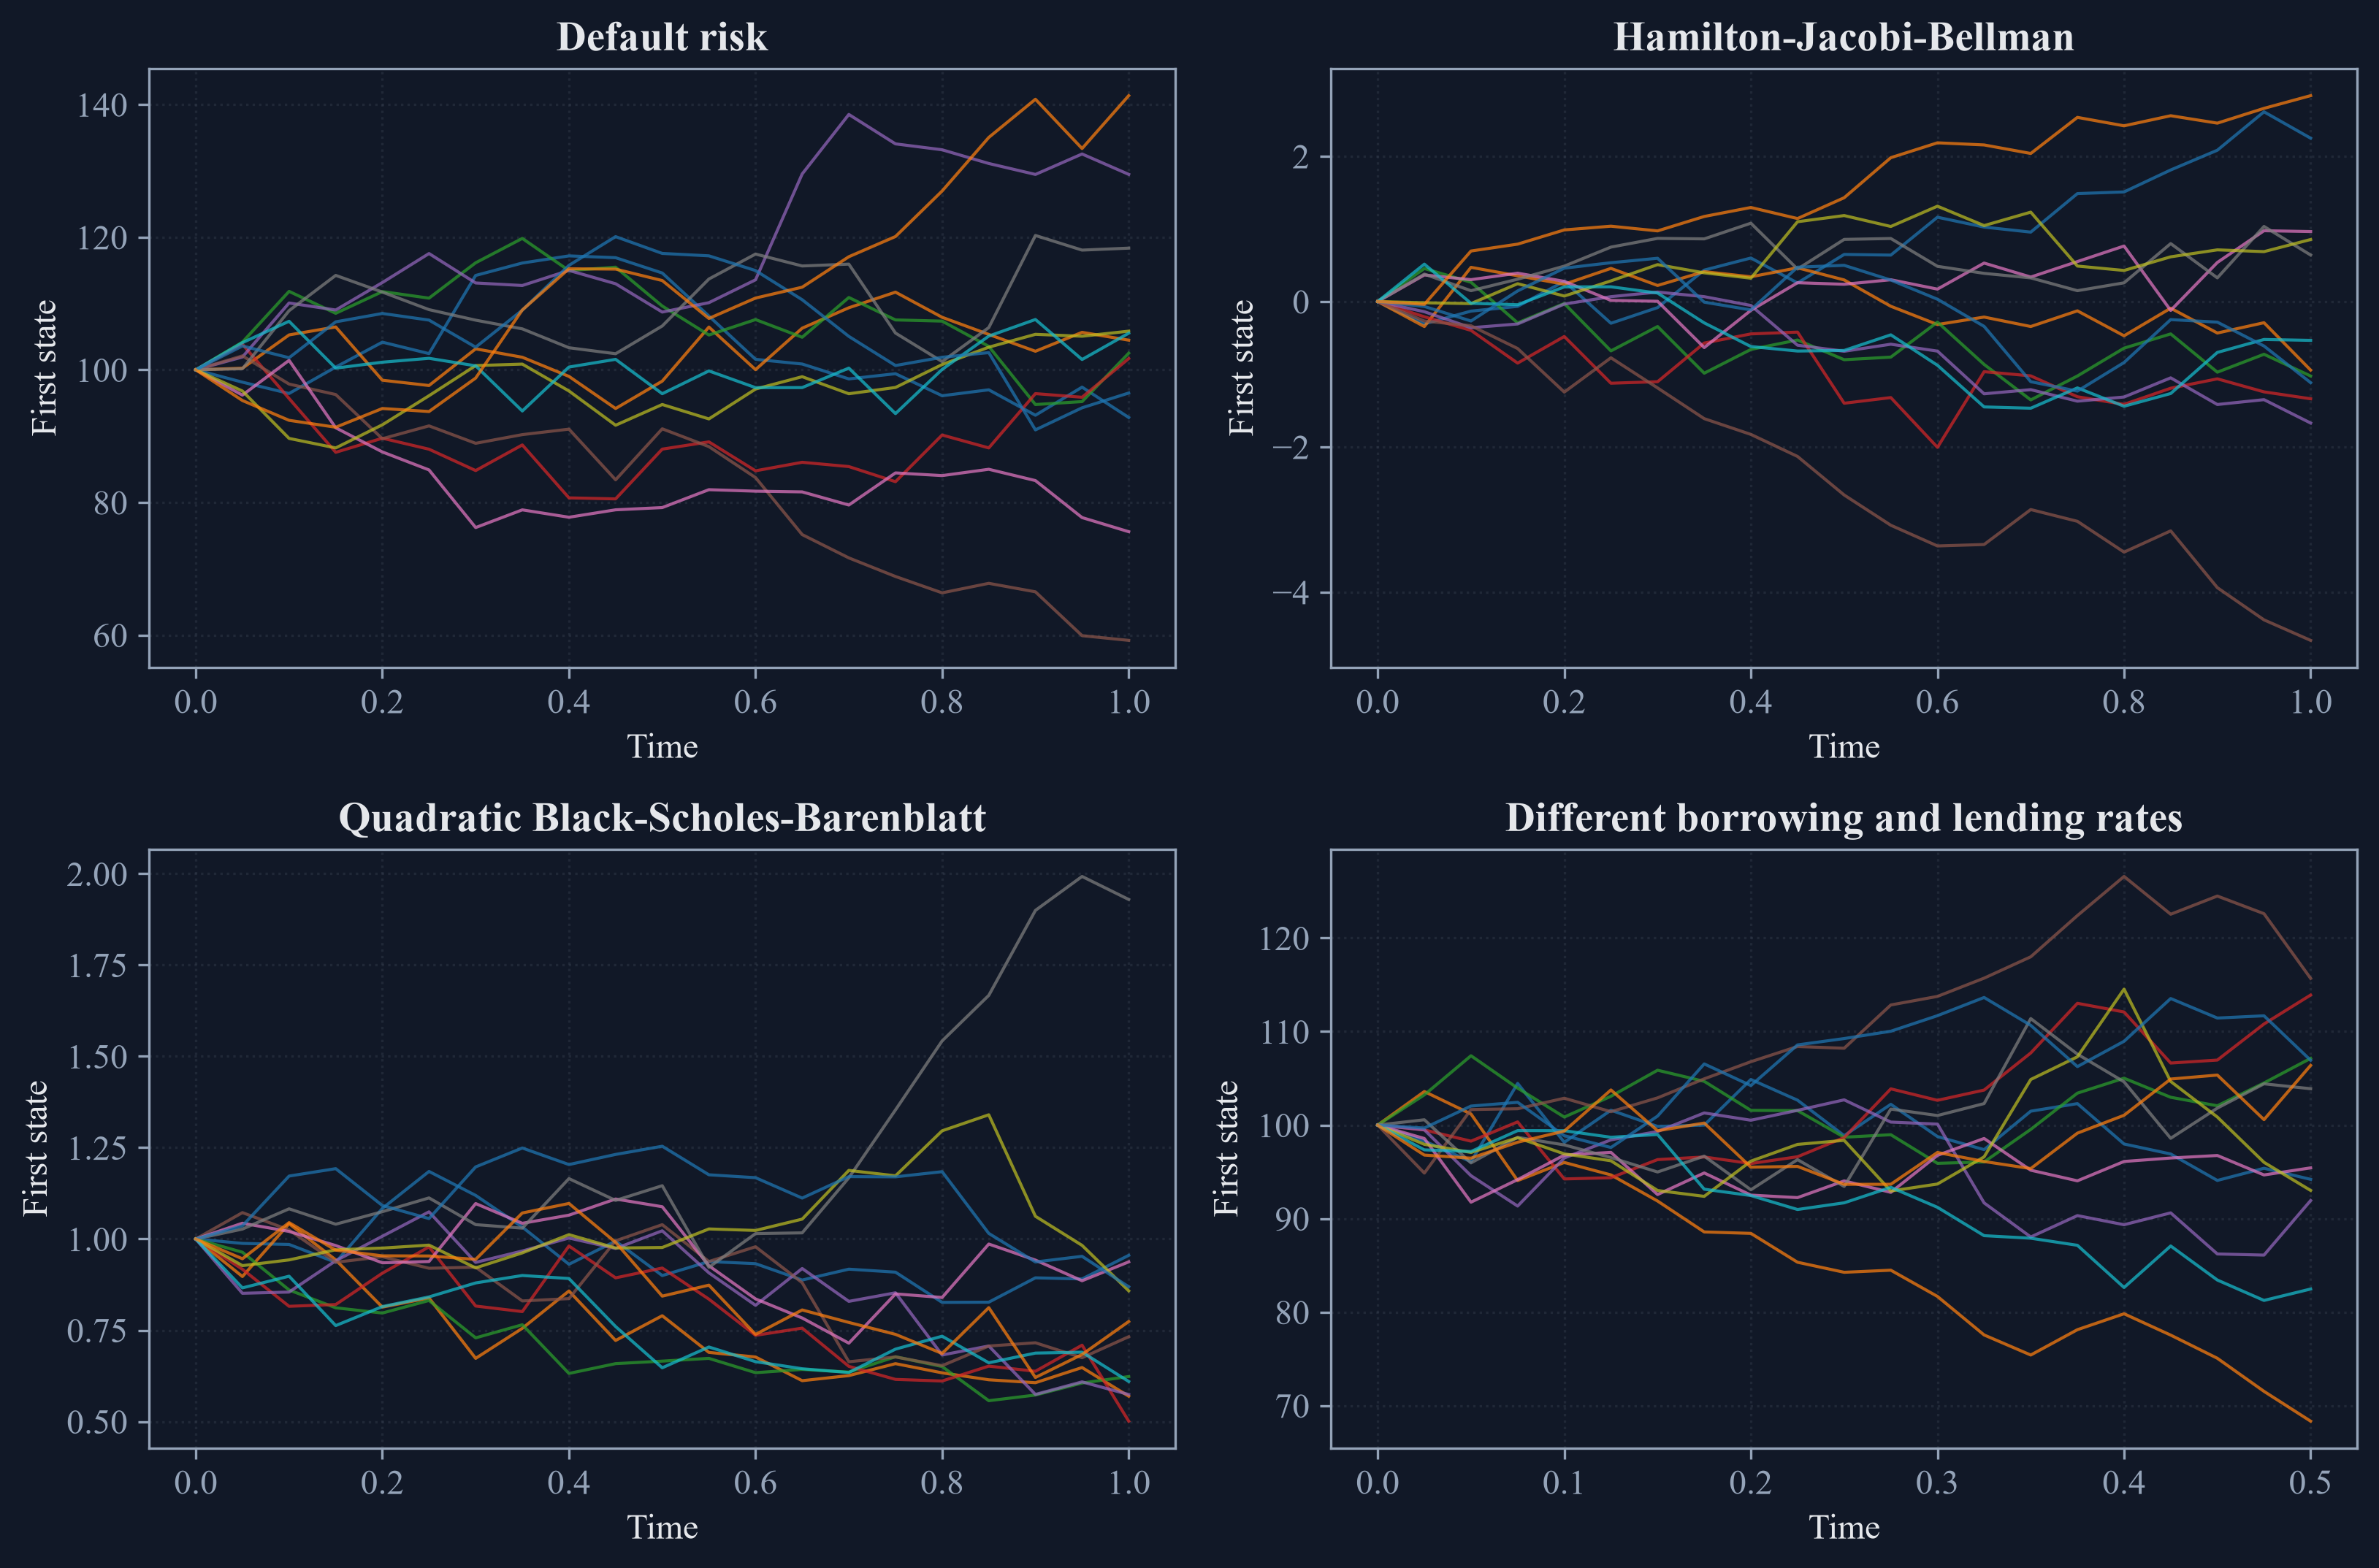

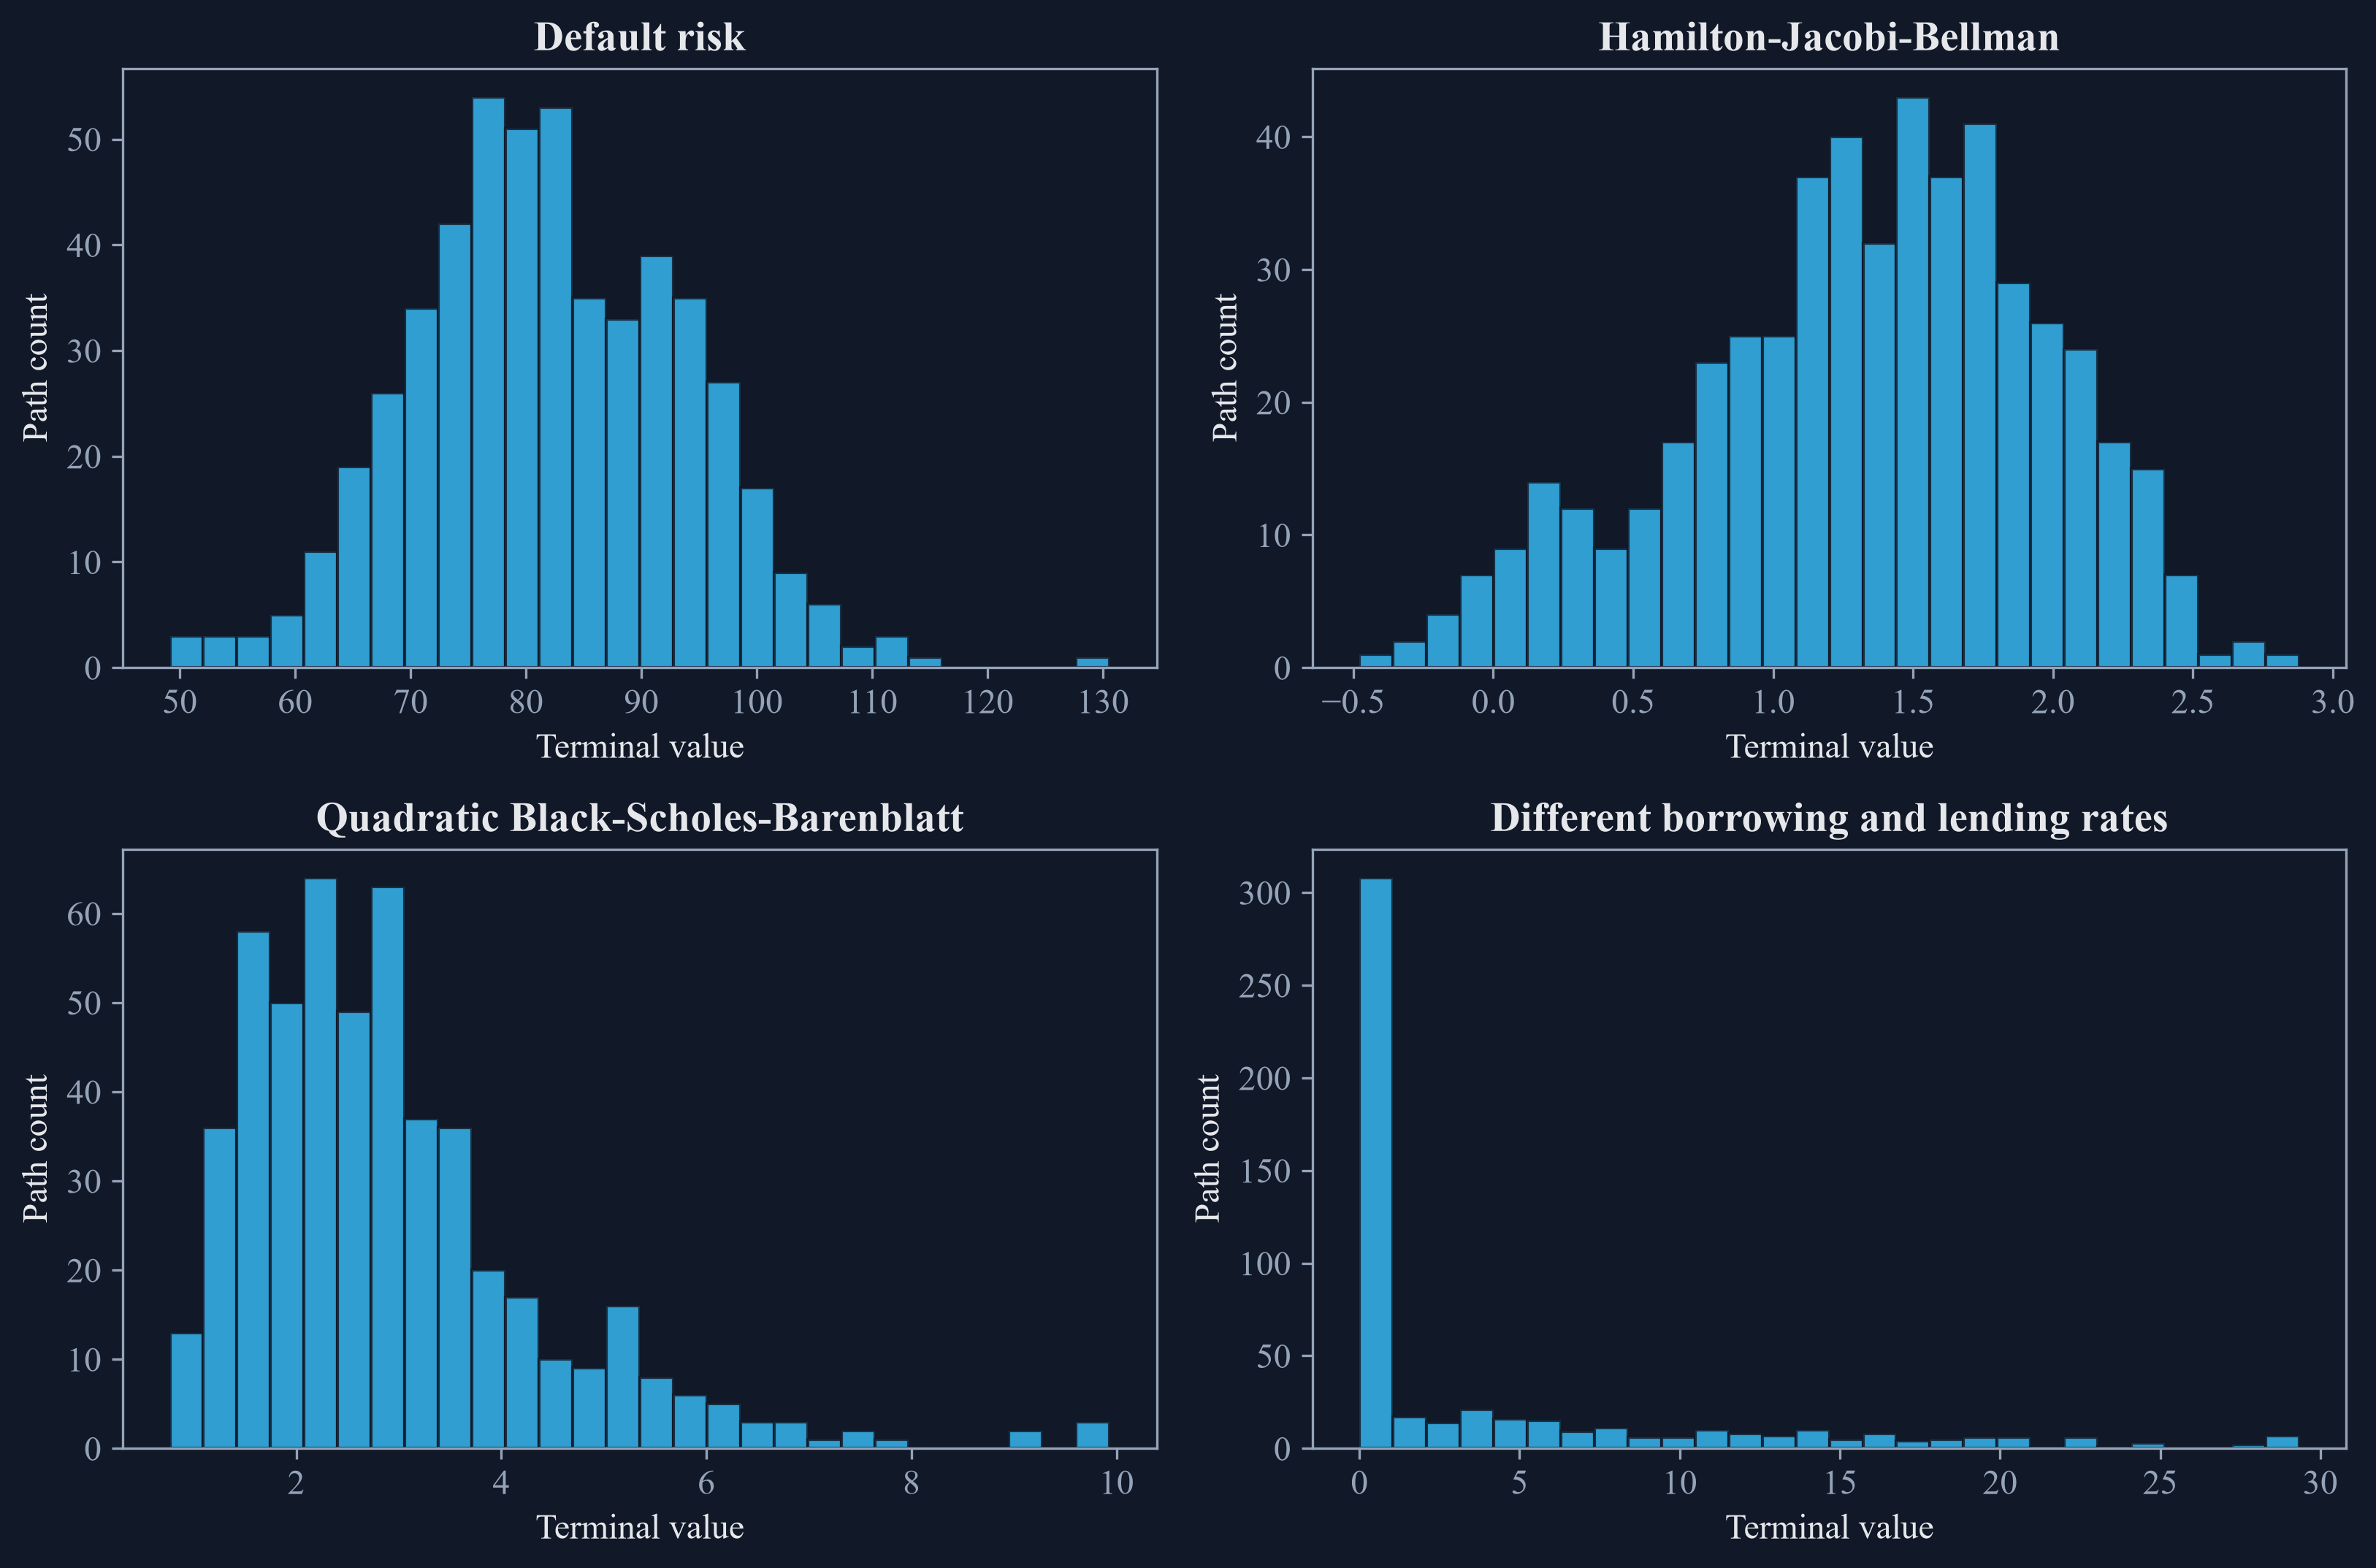

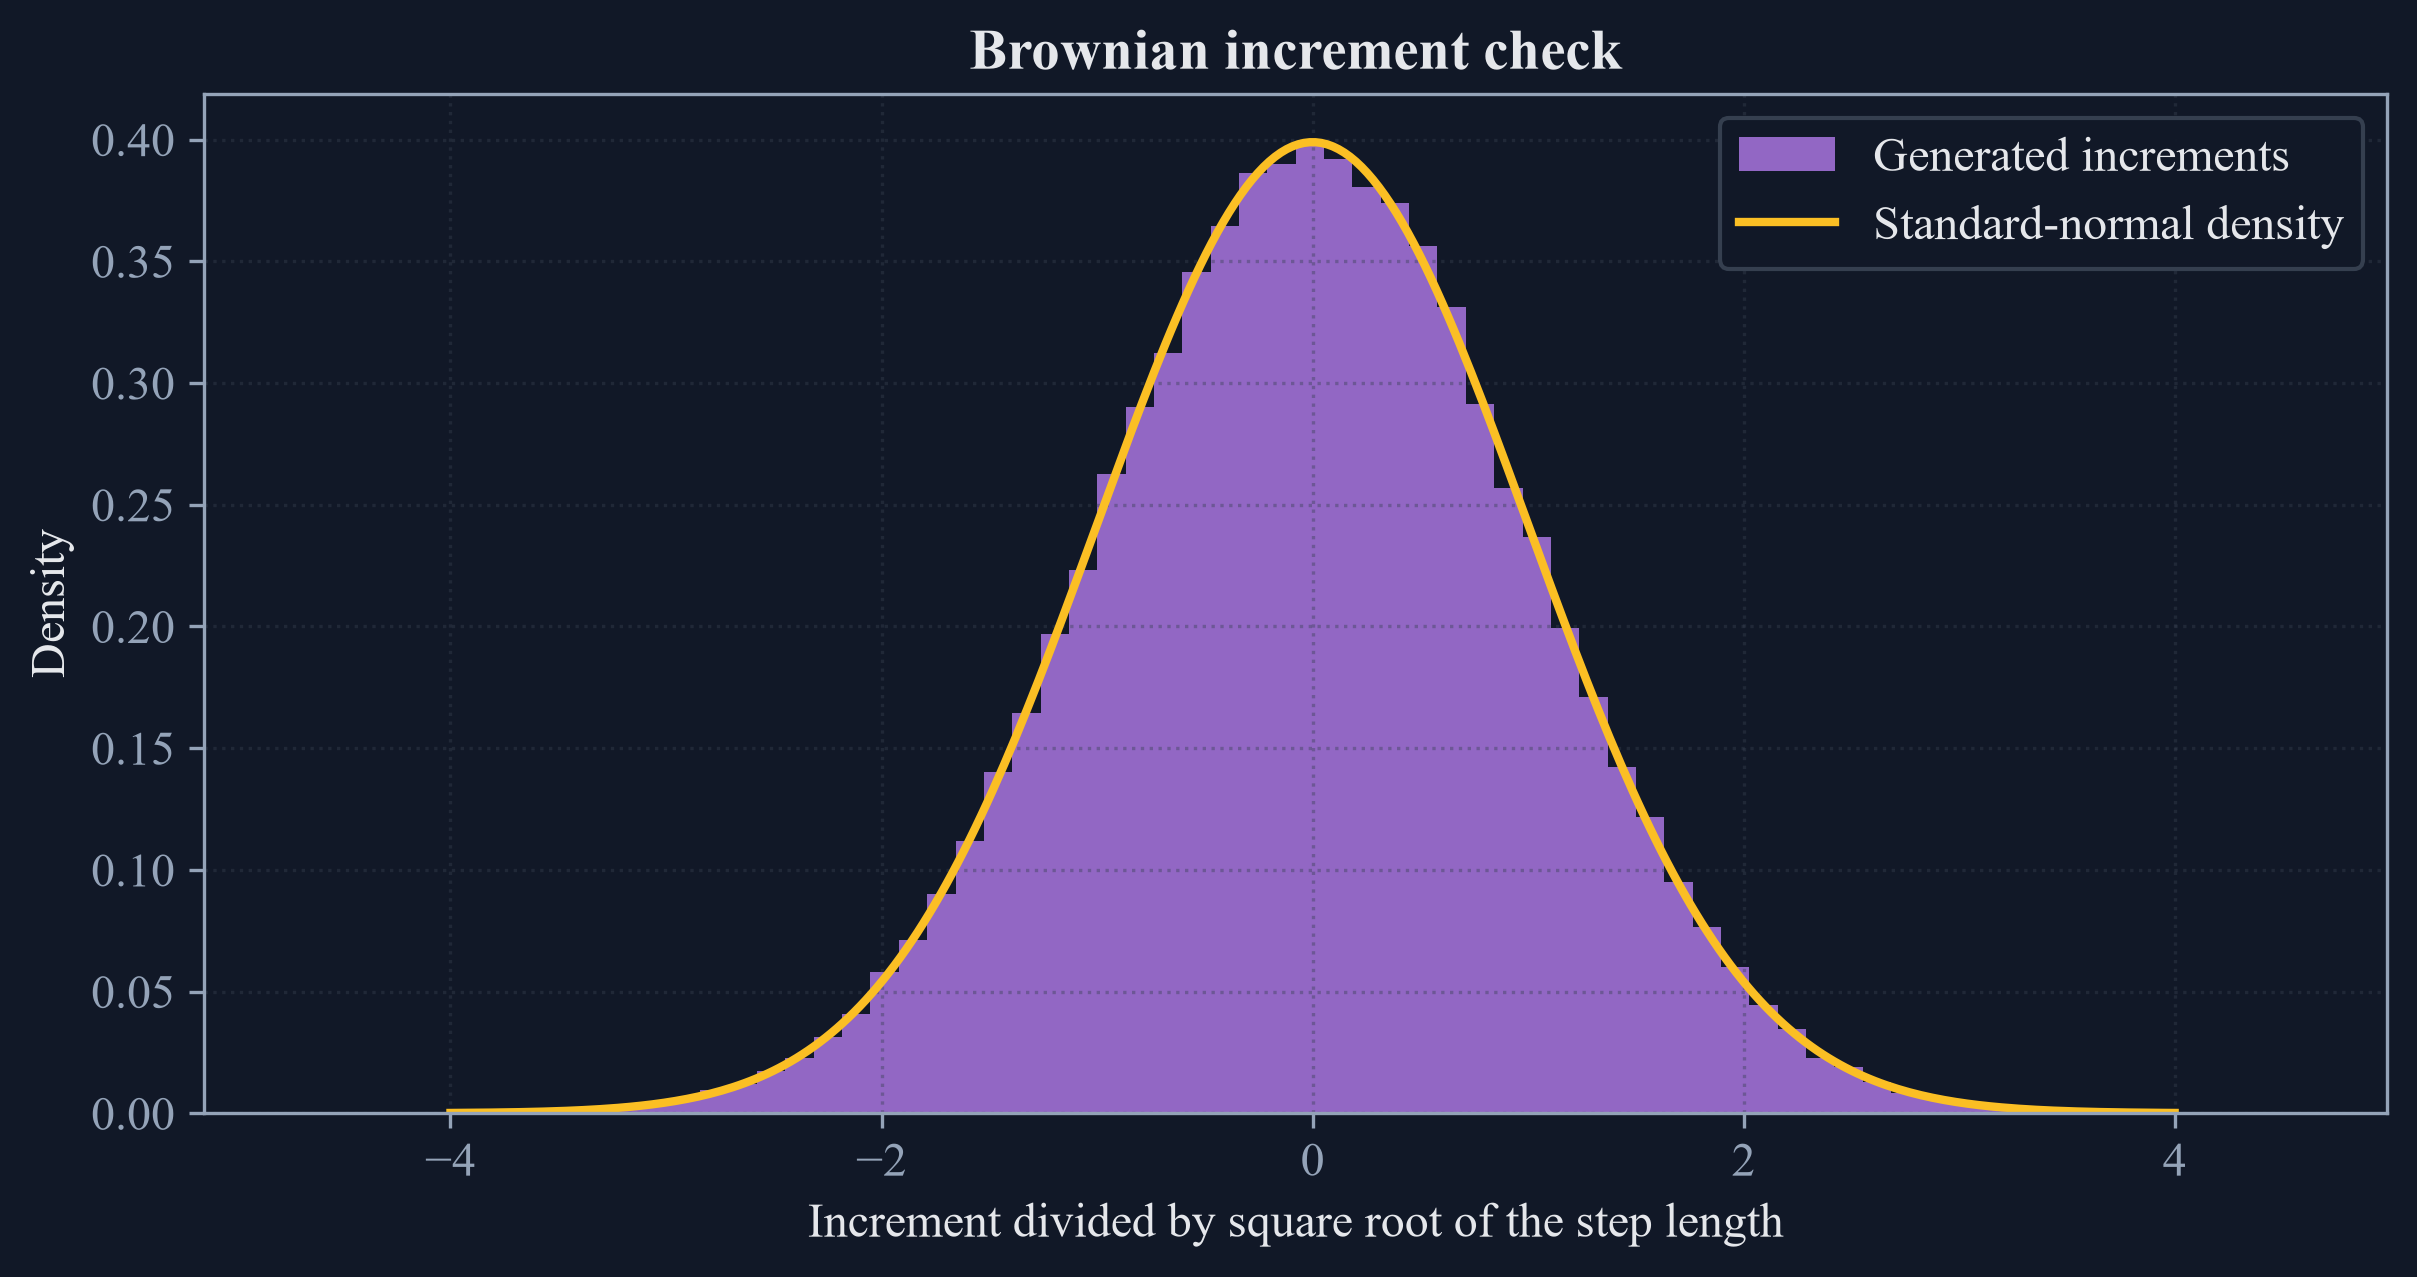

In [3]:
shape_rows = []
moment_rows = []
terminal_rows = []
sampled = {}
for position, (name, equation) in enumerate(equations):
    np.random.seed(2901 + position)
    dw, paths = equation.sample(512)
    sampled[name] = (dw, paths)
    normalized = dw.reshape(-1) / equation.sqrt_delta_t
    terminal_tensor = torch.tensor(paths[:, :, -1], dtype=torch.float32)
    payoff = equation.terminal(equation.total_time, terminal_tensor).detach().cpu().numpy().reshape(-1)
    shape_rows.append({"Equation": name, "Increment paths": dw.shape[0], "Dimension": dw.shape[1], "Time intervals": dw.shape[2], "State times": paths.shape[2]})
    moment_rows.append({"Equation": name, "Standardized increment mean": normalized.mean(), "Standardized increment variance": normalized.var(ddof=1), "Lag-one correlation": np.corrcoef(normalized[:-1], normalized[1:])[0, 1]})
    terminal_rows.append({"Equation": name, "Terminal payoff mean": payoff.mean(), "Terminal payoff standard deviation": payoff.std(ddof=1), "Terminal payoff minimum": payoff.min(), "Terminal payoff maximum": payoff.max()})
shape_table = pd.DataFrame(shape_rows)
moment_table = pd.DataFrame(moment_rows)
terminal_table = pd.DataFrame(terminal_rows)
save_table(shape_table, "forward_path_shapes", "Shapes of the newly generated increments and state paths.", "tab:chapter29-path-shapes")
save_table(moment_table, "brownian_moments", "Sample checks for standardized Brownian increments.", "tab:chapter29-brownian-moments")
save_table(terminal_table, "terminal_payoff_diagnostics", "Terminal-value summaries from newly generated model paths.", "tab:chapter29-terminal-diagnostics")
display(shape_table)
display(moment_table)
display(terminal_table)

figure, axes = plt.subplots(2, 2, figsize=(11.0, 7.3))
for axis, (name, equation) in zip(axes.flat, equations):
    dw, paths = sampled[name]
    times = np.linspace(0.0, equation.total_time, equation.num_time_interval + 1)
    for path in paths[:12, 0, :]:
        axis.plot(times, path, linewidth=1.0, alpha=0.72)
    axis.set_title(name)
    axis.set_xlabel("Time")
    axis.set_ylabel("First state")
    axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "forward_model_paths")

figure, axes = plt.subplots(2, 2, figsize=(11.0, 7.3))
for axis, row in zip(axes.flat, terminal_rows):
    values = equations[[item[0] for item in equations].index(row["Equation"])][1]
    dw, paths = sampled[row["Equation"]]
    payoff = values.terminal(values.total_time, torch.tensor(paths[:, :, -1], dtype=torch.float32)).detach().cpu().numpy().reshape(-1)
    axis.hist(payoff, bins=28, color=palette["cyan"], alpha=0.82, edgecolor=palette["background"])
    axis.set_title(row["Equation"])
    axis.set_xlabel("Terminal value")
    axis.set_ylabel("Path count")
figure.tight_layout()
save_figure(figure, "terminal_payoff_distributions")

all_standardized = np.concatenate([item[0].reshape(-1) / equation.sqrt_delta_t for (_, equation), item in zip(equations, sampled.values())])
figure, axis = plt.subplots(figsize=(8.2, 4.4))
axis.hist(all_standardized, bins=70, density=True, color=palette["violet"], alpha=0.74, label="Generated increments")
grid = np.linspace(-4.0, 4.0, 300)
density = np.exp(-0.5 * grid**2) / np.sqrt(2.0 * np.pi)
axis.plot(grid, density, color=palette["amber"], linewidth=2.0, label="Standard-normal density")
axis.set_xlabel("Increment divided by square root of the step length")
axis.set_ylabel("Density")
axis.set_title("Brownian increment check")
axis.legend()
axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "brownian_increment_distribution")

## Euler-Maruyama Time Steps

The Euler-Maruyama update on a grid $t_n=n\Delta t$ is:

$$
X_{n+1}=X_n+\mu(t_n,X_n)\Delta t+\sigma(t_n,X_n)\Delta W_n,
\qquad \Delta W_n\sim\mathcal N(0,\Delta t\,I_d).
$$

Here, $n$ labels the time interval; $\Delta t=T/N$ is the step length; $N$ is the number of intervals; $I_d$ is the $d$-dimensional identity matrix; $\Delta W_n$ is the Brownian increment; and $X_n$ approximates the state at $t_n$.

,Time intervals,Step length,Root mean squared state error,Maximum absolute state error
0,5,0.2,0.043308,1.276037
1,10,0.1,0.030238,0.488694
2,20,0.05,0.021829,0.394155
3,40,0.025,0.015324,0.172143
4,80,0.0125,0.011008,0.107421


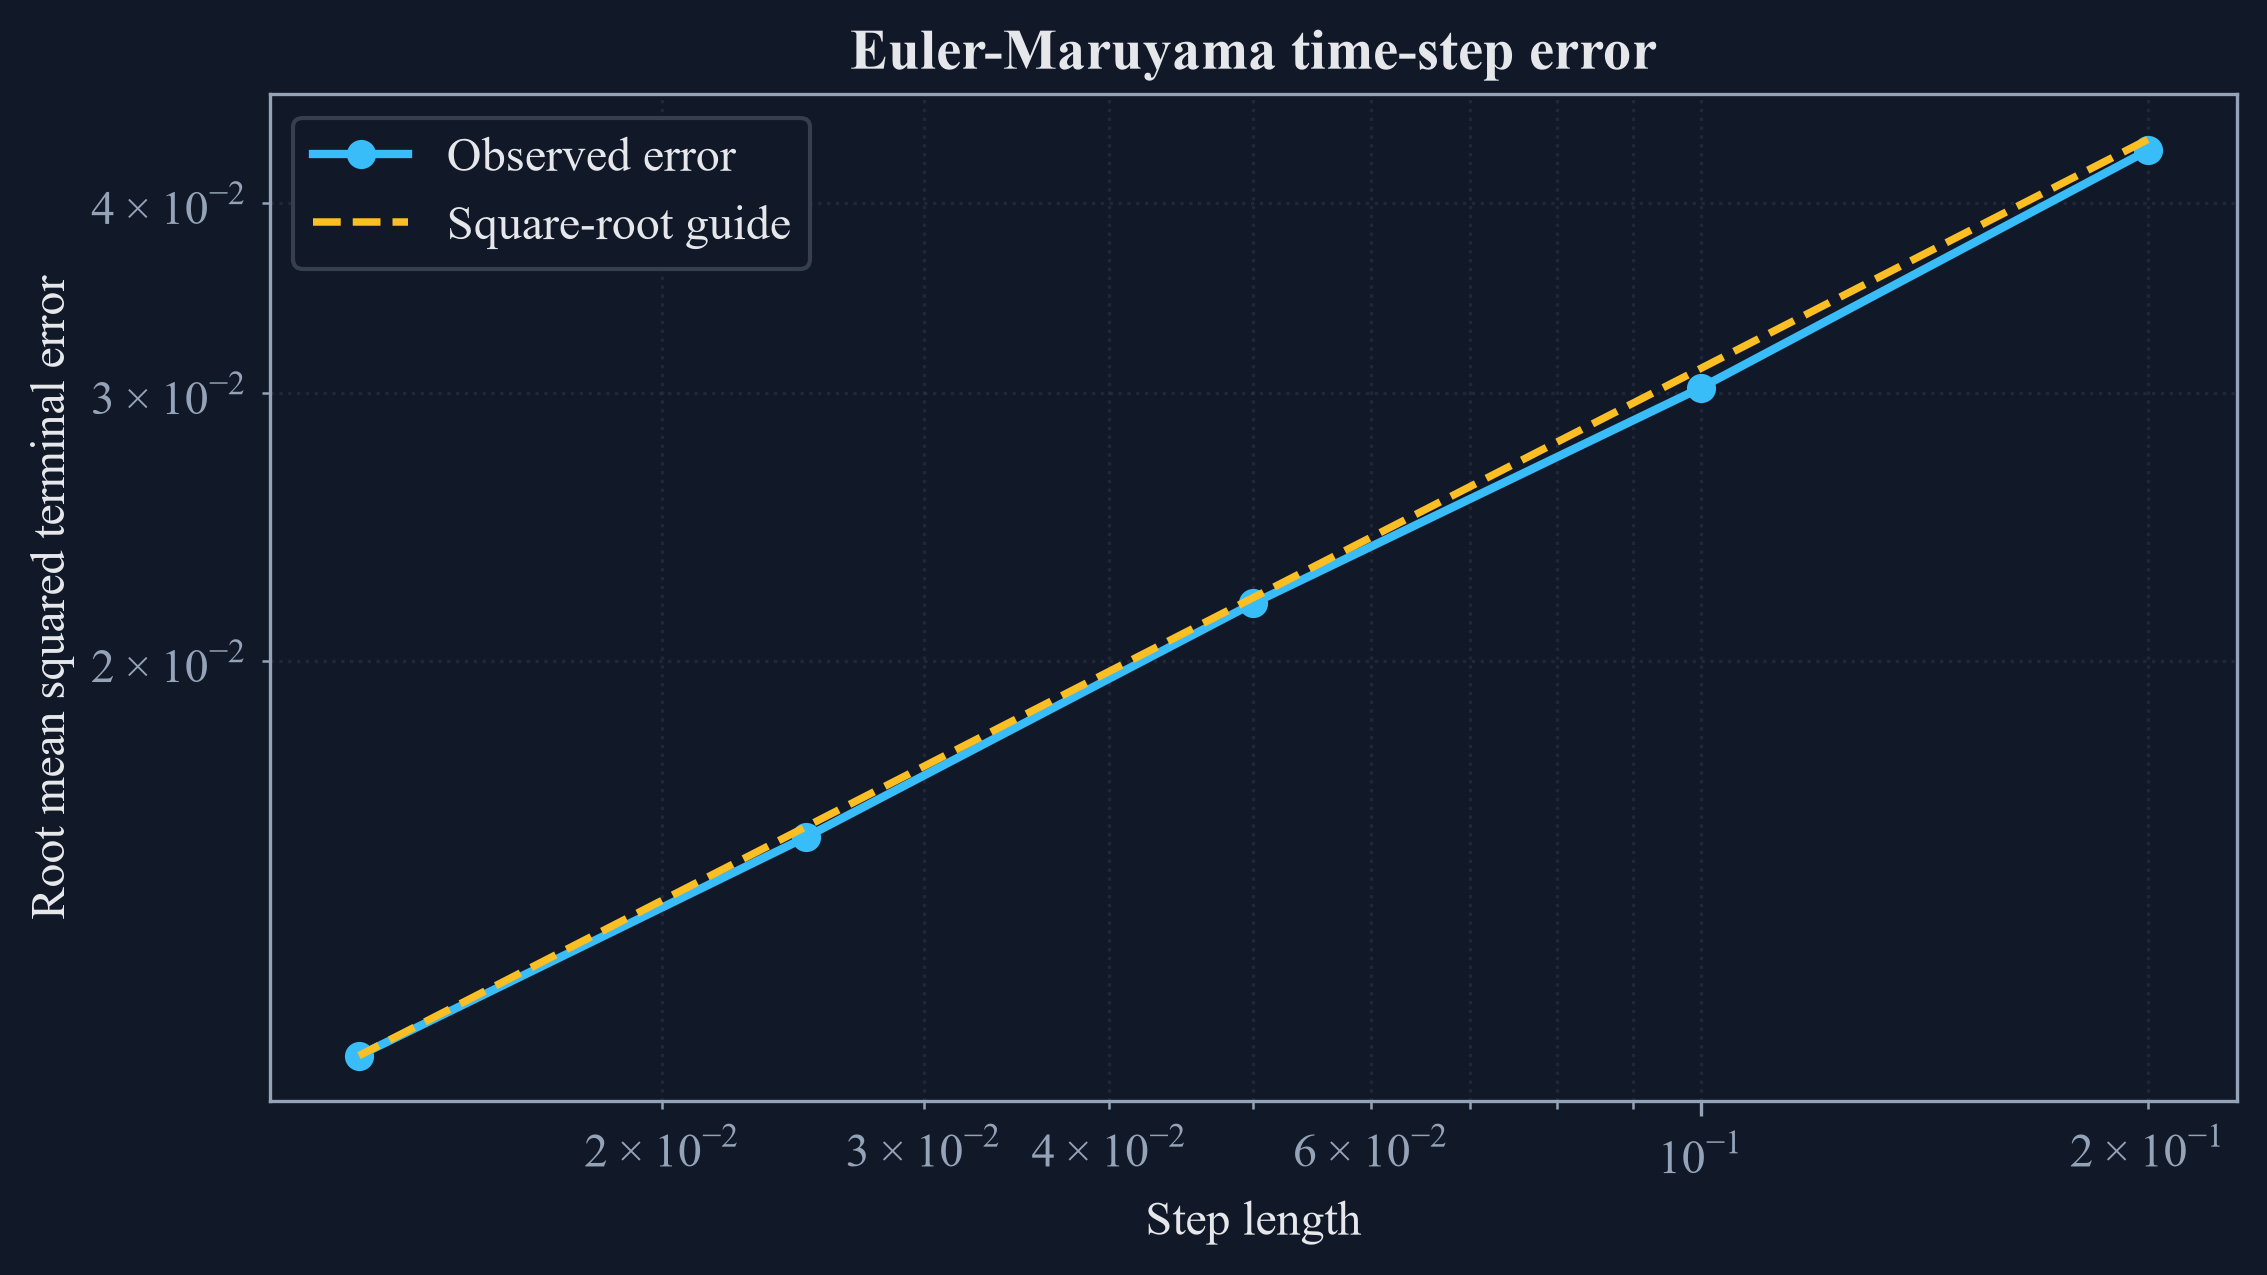

In [4]:
euler_rows = []
for steps in (5, 10, 20, 40, 80):
    equation = BlackScholesBarenblatt({"dim": 4, "total_time": 1.0, "num_time_interval": steps})
    np.random.seed(2920 + steps)
    dw, paths = equation.sample(4000)
    exact_terminal = equation.x_init[None, :] * np.exp(-0.5 * equation.sigma**2 * equation.total_time + equation.sigma * dw.sum(axis=2))
    error = paths[:, :, -1] - exact_terminal
    euler_rows.append({"Time intervals": steps, "Step length": equation.delta_t, "Root mean squared state error": np.sqrt(np.mean(error**2)), "Maximum absolute state error": np.max(np.abs(error))})
euler_table = pd.DataFrame(euler_rows)
save_table(euler_table, "euler_time_step_error", "Euler-Maruyama error against the exact fixed-volatility update.", "tab:chapter29-euler-error")
display(euler_table)

figure, axis = plt.subplots(figsize=(7.7, 4.4))
axis.loglog(euler_table["Step length"], euler_table["Root mean squared state error"], marker="o", color=palette["cyan"], linewidth=2.0, label="Observed error")
guide = euler_table["Root mean squared state error"].iloc[-1] * np.sqrt(euler_table["Step length"] / euler_table["Step length"].iloc[-1])
axis.loglog(euler_table["Step length"], guide, linestyle="--", color=palette["amber"], linewidth=1.8, label="Square-root guide")
axis.set_xlabel("Step length")
axis.set_ylabel("Root mean squared terminal error")
axis.set_title("Euler-Maruyama time-step error")
axis.grid(True, which="both", alpha=0.4)
axis.legend()
figure.tight_layout()
save_figure(figure, "euler_time_step_convergence")

## Linking backward values to terminal payoffs

The backward process associated with the equation is:

$$
dY_t=-f(t,X_t,Y_t,Z_t)\,dt+Z_t^{\mathsf T}dW_t,
\qquad Y_T=g(X_T),
\qquad Y_t=u(t,X_t).
$$

Here, $Y_t$ is the value process; $Z_t$ is the Brownian exposure or control; $f$ is the driver; $g(X_T)$ is the terminal value; and $u(t,X_t)$ links the backward value to the partial differential equation when the required regularity and integrability conditions hold.

In [5]:
generator_rows = []
helper_rows = []
for position, (name, equation) in enumerate(equations):
    np.random.seed(2950 + position)
    dw, paths = equation.sample(64)
    state = torch.tensor(paths[:, :, 3], dtype=torch.float32)
    value = torch.full((64, 1), 1.25, dtype=torch.float32)
    control = torch.linspace(-0.15, 0.15, steps=64 * equation.dim, dtype=torch.float32).reshape(64, equation.dim)
    rate = equation.r_u(0.15, state, value, control)
    hamiltonian = equation.h_z(0.15, state, value, control)
    terminal_state = torch.tensor(paths[:, :, -1], dtype=torch.float32)
    direct = equation.terminal(equation.total_time, terminal_state).reshape(-1)
    sample_state = terminal_state.unsqueeze(0)
    helper = equation.terminal_for_sample(sample_state).reshape(-1)
    agreement = bool(torch.allclose(direct, helper, atol=1e-6, rtol=1e-6))
    generator_rows.append({"Equation": name, "Rate mean": float(rate.mean()), "Hamiltonian mean": float(hamiltonian.mean()), "Rate finite": bool(torch.isfinite(rate).all()), "Hamiltonian finite": bool(torch.isfinite(hamiltonian).all())})
    helper_rows.append({"Equation": name, "Direct terminal values": direct.numel(), "Helper terminal values": helper.numel(), "Values agree": agreement, "Maximum absolute difference": float(torch.max(torch.abs(direct - helper)))})
generator_table = pd.DataFrame(generator_rows)
helper_table = pd.DataFrame(helper_rows)
save_table(generator_table, "generator_function_checks", "Finite-value checks for the released rate and Hamiltonian functions.", "tab:chapter29-generator-checks")
save_table(helper_table, "terminal_helper_checks", "Direct and multi-sample terminal-value comparison.", "tab:chapter29-terminal-helper")
display(generator_table)
display(helper_table)

,Equation,Rate mean,Hamiltonian mean,Rate finite,Hamiltonian finite
0,Default risk,0.086667,0,True,True
1,Hamilton-Jacobi-Bellman,0,0.015118,True,True
2,Quadratic Black-Scholes-Barenblatt,0.05,0,True,True
3,Different borrowing and lending rates,0.045937,-0.012574,True,True


,Equation,Direct terminal values,Helper terminal values,Values agree,Maximum absolute difference
0,Default risk,64,64,True,0
1,Hamilton-Jacobi-Bellman,64,64,True,0
2,Quadratic Black-Scholes-Barenblatt,64,64,True,0
3,Different borrowing and lending rates,64,64,False,30.113434


## Tests

In [6]:
assert len(public_table) == 21
assert set(parameter_table["Dimension"]) == {4}
assert all(tuple(sampled[name][0].shape) == (512, 4, 20) for name, _ in equations)
assert all(tuple(sampled[name][1].shape) == (512, 4, 21) for name, _ in equations)
assert np.max(np.abs(moment_table["Standardized increment mean"])) < 0.03
assert np.max(np.abs(moment_table["Standardized increment variance"] - 1.0)) < 0.04
assert euler_table["Root mean squared state error"].iloc[-1] < euler_table["Root mean squared state error"].iloc[0]
assert generator_table["Rate finite"].all()
assert generator_table["Hamiltonian finite"].all()
mismatch = helper_table.loc[helper_table["Equation"] == "Different borrowing and lending rates", "Values agree"].iloc[0]
assert not bool(mismatch)
assert helper_table.loc[helper_table["Equation"] != "Different borrowing and lending rates", "Values agree"].all()
display(pd.DataFrame({"Test": ["Public surface", "Path shapes", "Brownian moments", "Euler refinement", "Finite generators", "Terminal helper mismatch exposed"], "Passed": [True, True, True, True, True, True]}))

,Test,Passed
0,Public surface,True
1,Path shapes,True
2,Brownian moments,True
3,Euler refinement,True
4,Finite generators,True
5,Terminal helper mismatch exposed,True
